# Лабораторная работа 1. Основы машинного обучения и предобработка данных

**ФИО:** Брунгардт Даниил Евгеньевич  

**Номер зачетной книжки:** не знаю :( 
    
**Вариант:** 3

Вариант 3: Wine Quality, многоклассовая классификация качества вина.


In [1]:
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    auc,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize

warnings.filterwarnings("ignore")

VARIANT = 3
SEED = VARIANT
TARGET = "quality"

random.seed(SEED)
np.random.seed(SEED)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

## Загрузка данных


In [2]:
DATA_DIR = Path(".")
red_path = DATA_DIR / "winequality-red.csv"
white_path = DATA_DIR / "winequality-white.csv"

red = pd.read_csv(red_path, sep=";")
red["wine_type"] = "red"

white = pd.read_csv(white_path, sep=";")
white["wine_type"] = "white"

df = pd.concat([red, white], ignore_index=True)

print(f"Размер объединенного датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())
display(df.info())

Размер объединенного датасета: 6497 строк, 13 столбцов


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


None

In [3]:
print("Количество пропусков по столбцам:")
display(df.isna().sum().to_frame("missing_count"))

print("Описательная статистика числовых признаков:")
display(df.describe().T)

Количество пропусков по столбцам:


,missing_count
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


## EDA



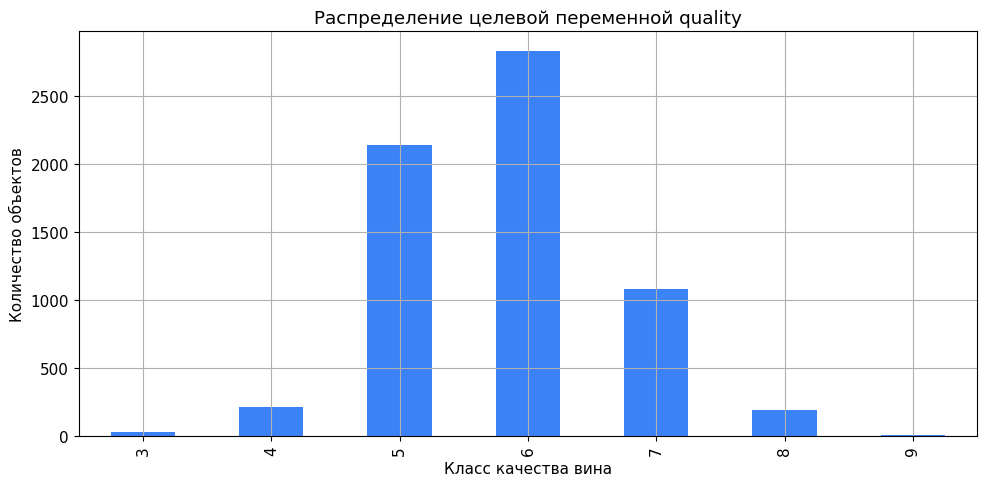

,count,share
quality,,
3,30,0.0046
4,216,0.0332
5,2138,0.3291
6,2836,0.4365
7,1079,0.1661
8,193,0.0297
9,5,0.0008


In [4]:
quality_counts = df[TARGET].value_counts().sort_index()

ax = quality_counts.plot(kind="bar", color="#3b82f6")
ax.set_title("Распределение целевой переменной quality")
ax.set_xlabel("Класс качества вина")
ax.set_ylabel("Количество объектов")
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "count": quality_counts,
        "share": (quality_counts / len(df)).round(4)
    })
)

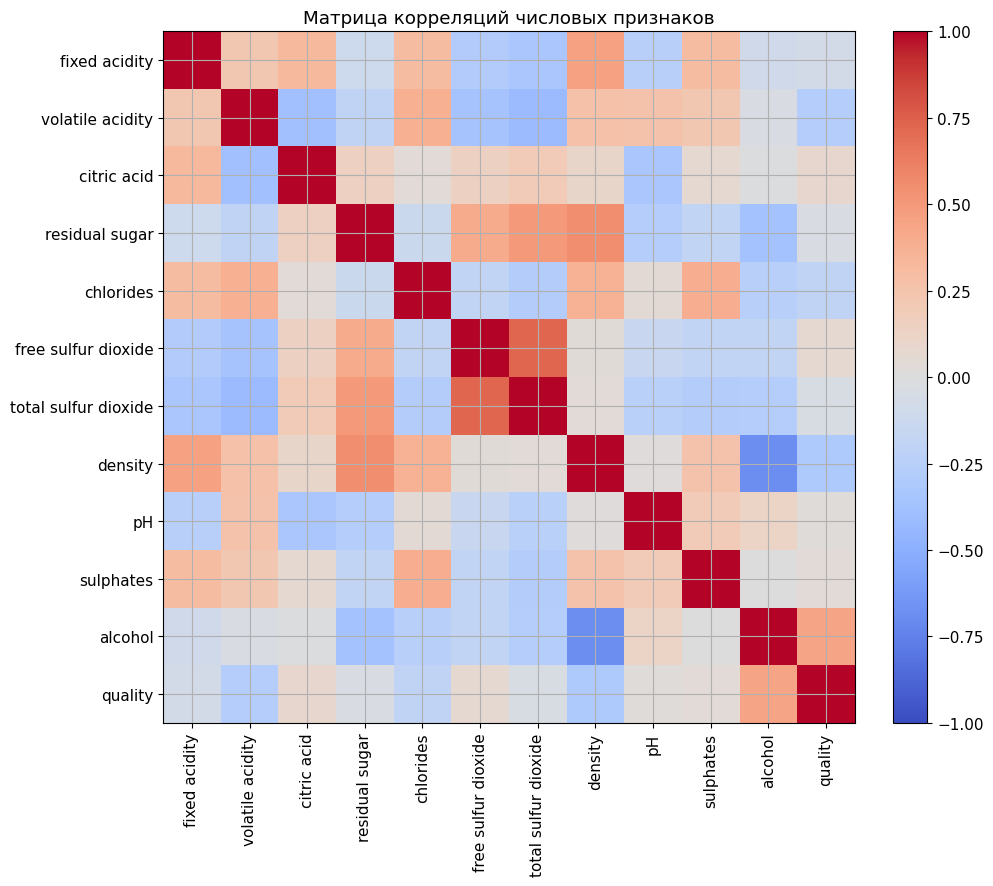

,corr_with_quality
alcohol,0.444319
density,-0.305858
volatile acidity,-0.265699
chlorides,-0.200666
citric acid,0.085532
fixed acidity,-0.076743
free sulfur dioxide,0.055463
total sulfur dioxide,-0.041385
sulphates,0.038485
residual sugar,-0.036980


In [5]:
numeric_cols_for_eda = df.select_dtypes(include="number").columns.tolist()
corr = df[numeric_cols_for_eda].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
ax.set_title("Матрица корреляций числовых признаков")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

display(corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False).to_frame("corr_with_quality"))

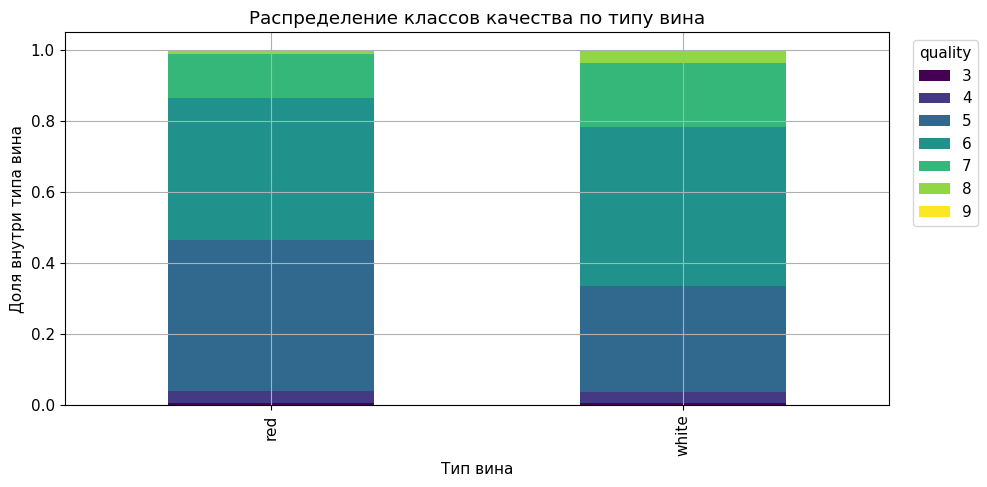

quality,3,4,5,6,7,8,9
wine_type,,,,,,,
red,10,53,681,638,199,18,0
white,20,163,1457,2198,880,175,5


In [6]:
wine_type_quality = pd.crosstab(df["wine_type"], df[TARGET], normalize="index")

ax = wine_type_quality.plot(kind="bar", stacked=True, colormap="viridis", figsize=(10, 5))
ax.set_title("Распределение классов качества по типу вина")
ax.set_xlabel("Тип вина")
ax.set_ylabel("Доля внутри типа вина")
ax.legend(title="quality", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(pd.crosstab(df["wine_type"], df[TARGET]))

## Feature engineering



In [7]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    eps = 1e-6
    data["sulfur_ratio"] = data["free sulfur dioxide"] / (data["total sulfur dioxide"] + eps)
    data["acid_balance"] = data["fixed acidity"] + data["citric acid"] - data["volatile acidity"]
    data["alcohol_sulphates"] = data["alcohol"] * data["sulphates"]
    data["sugar_alcohol_ratio"] = data["residual sugar"] / (data["alcohol"] + eps)
    return data

df_model = add_features(df)
display(df_model[["sulfur_ratio", "acid_balance", "alcohol_sulphates", "sugar_alcohol_ratio"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
sulfur_ratio,6497.0,0.286768,0.124645,0.022727,0.202073,0.269767,0.348837,0.857143
acid_balance,6497.0,7.194274,1.332593,3.510000,6.380000,6.960000,7.670000,16.190000
alcohol_sulphates,6497.0,5.573423,1.698796,2.625000,4.400000,5.208000,6.348000,19.404000
sugar_alcohol_ratio,6497.0,0.544638,0.510343,0.056604,0.170000,0.283186,0.812500,5.623931


## Обработка выбросов

Для числовых признаков используется IQR-клиппинг. Границы выбросов обучаются только на `X_train`, а к тестовой выборке применяется только `transform`. Так мы не допускаем утечки статистик из теста.

In [8]:
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        q1 = X_df.quantile(0.25)
        q3 = X_df.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = (q1 - self.factor * iqr).to_numpy(dtype=float)
        self.upper_ = (q3 + self.factor * iqr).to_numpy(dtype=float)
        return self

    def transform(self, X):
        X_arr = np.asarray(X, dtype=float)
        return np.clip(X_arr, self.lower_, self.upper_)


X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

numerical_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Числовые признаки:", numerical_cols)
print("Категориальные признаки:", categorical_cols)

Числовые признаки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'sulfur_ratio', 'acid_balance', 'alcohol_sulphates', 'sugar_alcohol_ratio']
Категориальные признаки: ['wine_type']


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y,
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Распределение классов в train:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("share"))
print("Распределение классов в test:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("share"))

Train: (5197, 16), Test: (1300, 16)
Распределение классов в train:


,share
quality,
3,0.004618
4,0.033288
5,0.329036
6,0.436598
7,0.166057
8,0.029632
9,0.000770


Распределение классов в test:


,share
quality,
3,0.004615
4,0.033077
5,0.329231
6,0.436154
7,0.166154
8,0.030000
9,0.000769


In [10]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("iqr_clipper", IQRClipper(factor=1.5)),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols),
    ],
    remainder="drop",
)

## Обучение трех базовых моделей



In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=VARIANT + 2),
    "Naive Bayes": GaussianNB(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = "f1_weighted"
results = []
fitted_pipelines = {}

for name, estimator in models.items():
    pipe = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", estimator),
        ]
    )
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=scoring)

    row = {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_weighted": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
        "roc_auc_ovr_weighted": roc_auc_score(
            y_test,
            y_proba,
            multi_class="ovr",
            average="weighted",
            labels=pipe.named_steps["model"].classes_,
        ),
        "cv_f1_mean": cv_scores.mean(),
        "cv_f1_std": cv_scores.std(),
    }
    results.append(row)
    fitted_pipelines[name] = pipe

results_df = pd.DataFrame(results).set_index("model").sort_values("cv_f1_mean", ascending=False)
display(results_df.style.format("{:.4f}"))

,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc_ovr_weighted,cv_f1_mean,cv_f1_std
model,,,,,,,
KNN,0.5662,0.5502,0.5662,0.5541,0.7426,0.5354,0.0088
Logistic Regression,0.5308,0.5041,0.5308,0.4995,0.7255,0.5173,0.0178
Naive Bayes,0.2715,0.5006,0.2715,0.3055,0.5758,0.3530,0.0555


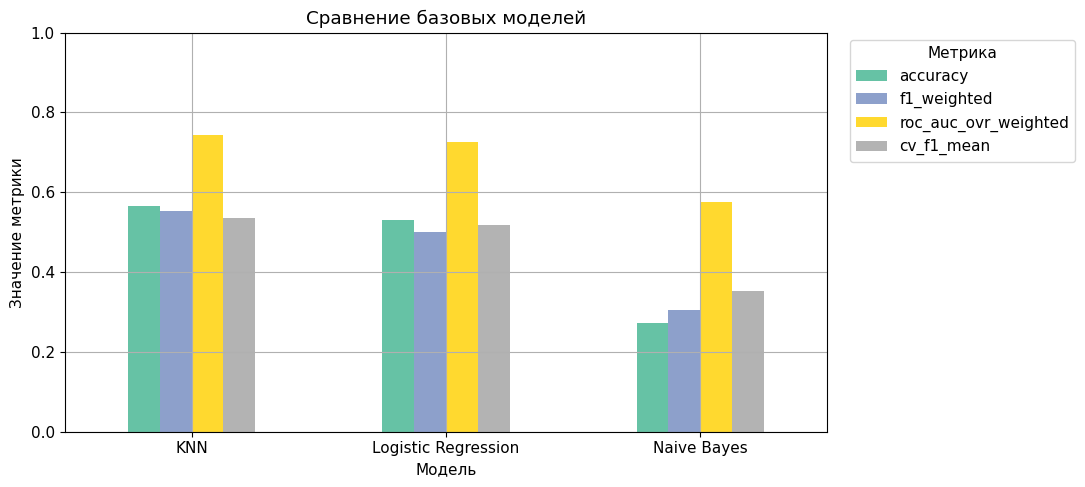

In [12]:
ax = results_df[["accuracy", "f1_weighted", "roc_auc_ovr_weighted", "cv_f1_mean"]].plot(
    kind="bar",
    figsize=(11, 5),
    colormap="Set2",
)
ax.set_title("Сравнение базовых моделей")
ax.set_xlabel("Модель")
ax.set_ylabel("Значение метрики")
ax.set_ylim(0, 1)
ax.legend(title="Метрика", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Подбор гиперпараметров


In [13]:
grid_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier()),
    ]
)

param_grid = {
    "model__n_neighbors": [3, 5, 7],
}

grid_search = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
grid_search.fit(X_train, y_train)

grid_results = pd.DataFrame(grid_search.cv_results_)[
    ["param_model__n_neighbors", "mean_test_score", "std_test_score", "mean_train_score"]
].sort_values("mean_test_score", ascending=False)

final_model = grid_search.best_estimator_
print("Лучшие параметры:", grid_search.best_params_)
display(grid_results.style.format({"mean_test_score": "{:.4f}", "std_test_score": "{:.4f}", "mean_train_score": "{:.4f}"}))

Лучшие параметры: {'model__n_neighbors': 3}


,param_model__n_neighbors,mean_test_score,std_test_score,mean_train_score
0,3,0.5444,0.0073,0.7683
2,7,0.5392,0.0109,0.6522
1,5,0.5354,0.0088,0.6838


In [14]:
final_pred = final_model.predict(X_test)
final_proba = final_model.predict_proba(X_test)

final_metrics = {
    "accuracy": accuracy_score(y_test, final_pred),
    "precision_weighted": precision_score(y_test, final_pred, average="weighted", zero_division=0),
    "recall_weighted": recall_score(y_test, final_pred, average="weighted", zero_division=0),
    "f1_weighted": f1_score(y_test, final_pred, average="weighted"),
    "roc_auc_ovr_weighted": roc_auc_score(
        y_test,
        final_proba,
        multi_class="ovr",
        average="weighted",
        labels=final_model.named_steps["model"].classes_,
    ),
}

print("Метрики лучшей модели на тестовой выборке:")
display(pd.Series(final_metrics).to_frame("value").style.format("{:.4f}"))
print("Classification report:")
print(classification_report(y_test, final_pred, zero_division=0))

Метрики лучшей модели на тестовой выборке:


,value
accuracy,0.5654
precision_weighted,0.5599
recall_weighted,0.5654
f1_weighted,0.5607
roc_auc_ovr_weighted,0.7416


Classification report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.21      0.21      0.21        43
           5       0.58      0.64      0.61       428
           6       0.60      0.62      0.61       567
           7       0.52      0.44      0.48       216
           8       0.37      0.18      0.24        39
           9       0.00      0.00      0.00         1

    accuracy                           0.57      1300
   macro avg       0.33      0.30      0.31      1300
weighted avg       0.56      0.57      0.56      1300



## Анализ ошибок



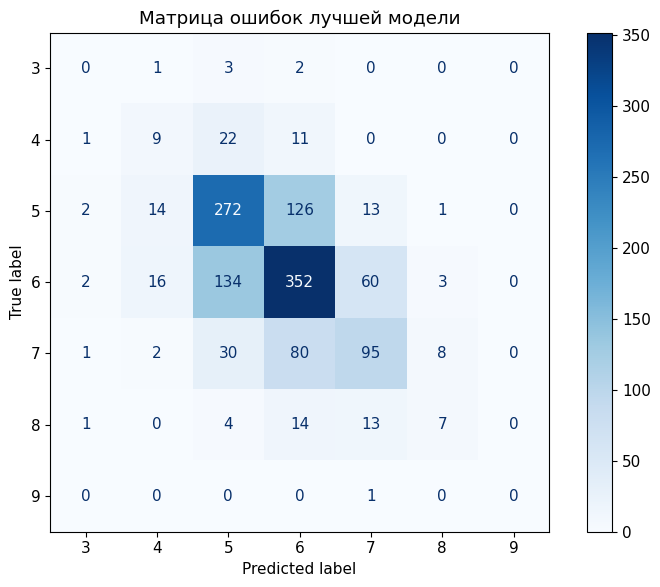

Количество ошибок на тесте: 565 из 1300


,wine_type,alcohol,volatile acidity,density,true_quality,pred_quality,absolute_error
2815,white,11.7,0.370,0.99060,8,3,5
3361,white,11.0,0.170,0.99160,7,3,4
5938,white,10.4,0.240,0.99232,8,5,3
4805,white,12.9,0.290,0.99130,7,4,3
5053,white,12.4,0.540,0.98918,5,8,3
2714,white,10.4,0.150,0.99280,8,5,3
832,red,9.9,0.440,0.99832,3,6,3
3011,white,12.3,0.300,0.99250,8,5,3
903,red,10.8,0.590,0.99620,7,4,3
5409,white,10.5,0.260,0.99705,3,6,3


In [15]:
labels = np.array(sorted(y.unique()))
cm = confusion_matrix(y_test, final_pred, labels=labels)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=True)
ax.set_title("Матрица ошибок лучшей модели")
ax.grid(False)
plt.tight_layout()
plt.show()

errors = X_test.copy()
errors["true_quality"] = y_test
errors["pred_quality"] = final_pred
errors["absolute_error"] = (errors["true_quality"] - errors["pred_quality"]).abs()
worst_errors = errors[errors["absolute_error"] > 0].sort_values("absolute_error", ascending=False)

print(f"Количество ошибок на тесте: {len(worst_errors)} из {len(X_test)}")
display(worst_errors[["wine_type", "alcohol", "volatile acidity", "density", "true_quality", "pred_quality", "absolute_error"]].head(15))

In [16]:
report_dict = classification_report(y_test, final_pred, output_dict=True, zero_division=0)
class_report = (
    pd.DataFrame(report_dict)
    .T
    .loc[[str(c) for c in labels], ["precision", "recall", "f1-score", "support"]]
)
display(class_report.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"}))

low_recall_classes = class_report.sort_values("recall").head(3)
print("Классы с наименьшим recall:")
display(low_recall_classes)

,precision,recall,f1-score,support
3,0.000,0.000,0.000,6
4,0.214,0.209,0.212,43
5,0.585,0.636,0.609,428
6,0.602,0.621,0.611,567
7,0.522,0.440,0.477,216
8,0.368,0.179,0.241,39
9,0.000,0.000,0.000,1


Классы с наименьшим recall:


,precision,recall,f1-score,support
3,0.000000,0.000000,0.000000,6.0
9,0.000000,0.000000,0.000000,1.0
8,0.368421,0.179487,0.241379,39.0


## ROC-кривые



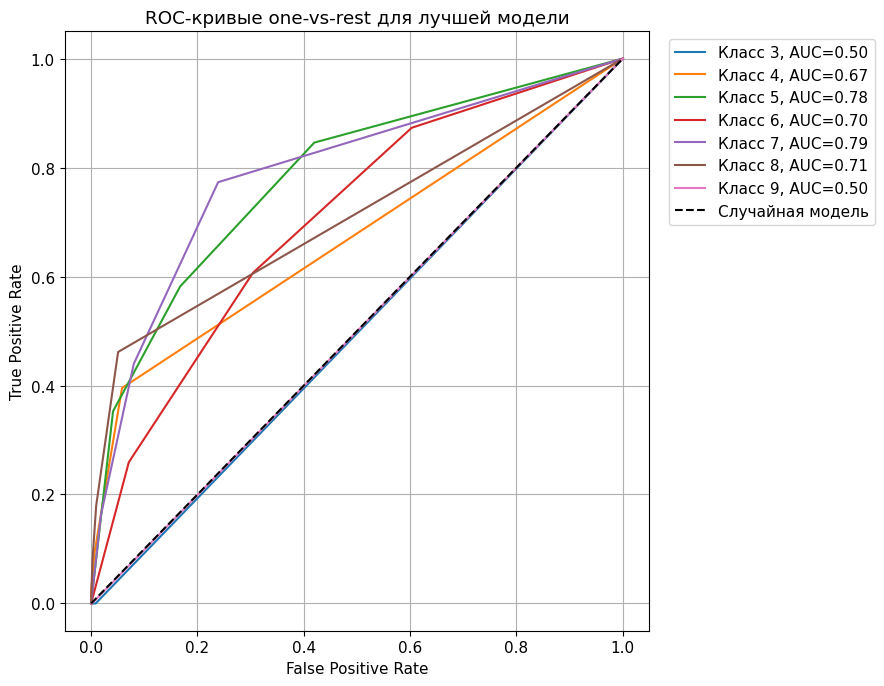

In [17]:
y_test_bin = label_binarize(y_test, classes=labels)

plt.figure(figsize=(9, 7))
for i, cls in enumerate(labels):
    if y_test_bin[:, i].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], final_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Класс {cls}, AUC={roc_auc:.2f}")

plt.plot([0, 1], [0, 1], "k--", label="Случайная модель")
plt.title("ROC-кривые one-vs-rest для лучшей модели")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Влияние признаков



,feature,importance_mean,importance_std
10,alcohol,0.0667,0.0051
8,pH,0.0510,0.0123
12,sulfur_ratio,0.0502,0.0074
1,volatile acidity,0.0492,0.0080
4,chlorides,0.0482,0.0109
2,citric acid,0.0422,0.0141
9,sulphates,0.0410,0.0077
14,alcohol_sulphates,0.0386,0.0083
5,free sulfur dioxide,0.0362,0.0057
3,residual sugar,0.0313,0.0082


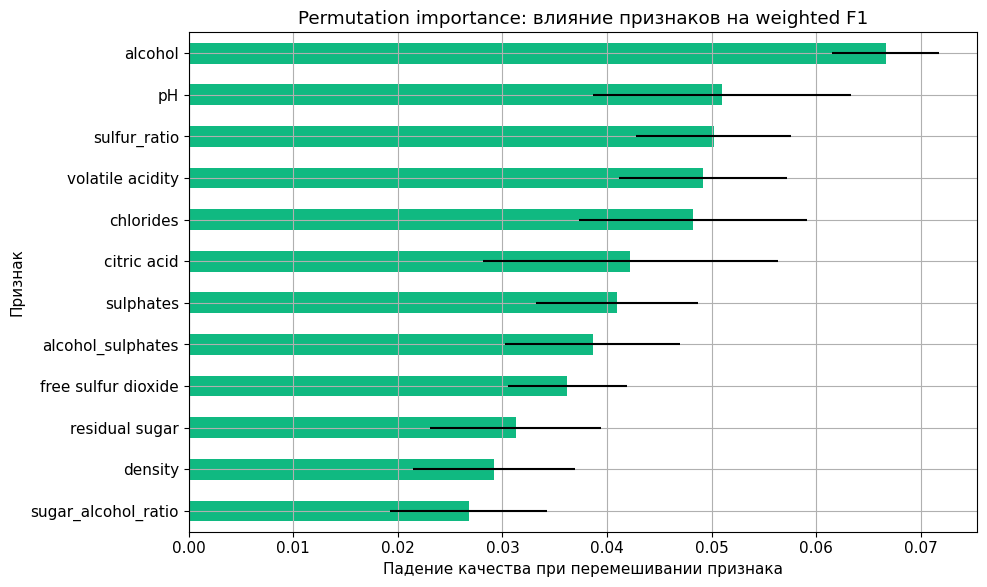

In [18]:
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring=scoring,
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1,
)

importance_df = pd.DataFrame(
    {
        "feature": X_test.columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    }
).sort_values("importance_mean", ascending=False)

display(importance_df.head(12).style.format({"importance_mean": "{:.4f}", "importance_std": "{:.4f}"}))

ax = importance_df.head(12).sort_values("importance_mean").plot(
    kind="barh",
    x="feature",
    y="importance_mean",
    xerr="importance_std",
    figsize=(10, 6),
    color="#10b981",
    legend=False,
)
ax.set_title("Permutation importance: влияние признаков на weighted F1")
ax.set_xlabel("Падение качества при перемешивании признака")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

## Анализ устойчивости



,train_fraction,train_size,train_f1_weighted,test_f1_weighted
0,0.3,1559,0.7119,0.4582
1,0.5,2598,0.7361,0.4842
2,0.7,3638,0.7593,0.5407
3,0.9,4679,0.7746,0.5508
4,1.0,5197,0.7800,0.5607


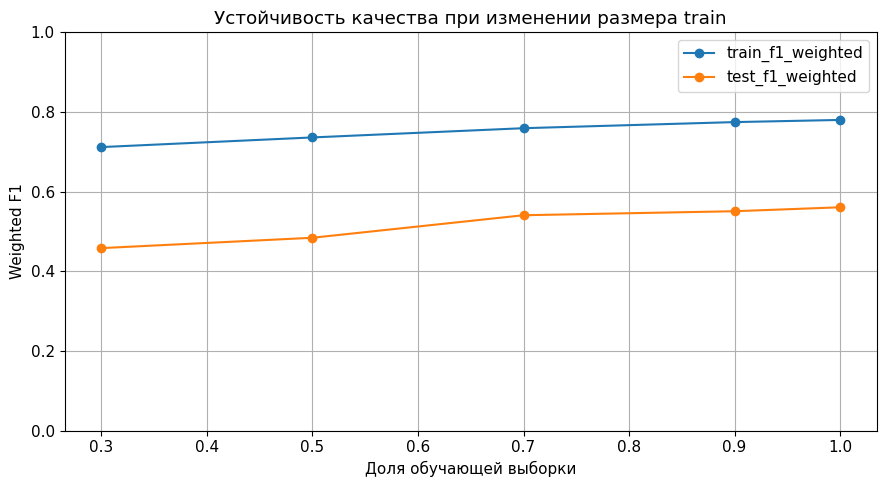

In [19]:
train_fractions = [0.3, 0.5, 0.7, 0.9, 1.0]
stability_rows = []

train_pool = X_train.copy()
train_pool[TARGET] = y_train

for frac in train_fractions:
    if frac < 1.0:
        subset = (
            train_pool
            .groupby(TARGET, group_keys=False)
            .sample(frac=frac, random_state=SEED)
        )
    else:
        subset = train_pool.copy()

    X_sub = subset.drop(columns=[TARGET])
    y_sub = subset[TARGET]

    model = clone(final_model)
    model.fit(X_sub, y_sub)
    train_pred = model.predict(X_sub)
    test_pred = model.predict(X_test)

    stability_rows.append(
        {
            "train_fraction": frac,
            "train_size": len(X_sub),
            "train_f1_weighted": f1_score(y_sub, train_pred, average="weighted"),
            "test_f1_weighted": f1_score(y_test, test_pred, average="weighted"),
        }
    )

stability_df = pd.DataFrame(stability_rows)
display(stability_df.style.format({"train_fraction": "{:.1f}", "train_f1_weighted": "{:.4f}", "test_f1_weighted": "{:.4f}"}))

ax = stability_df.plot(
    x="train_fraction",
    y=["train_f1_weighted", "test_f1_weighted"],
    marker="o",
    figsize=(9, 5),
)
ax.set_title("Устойчивость качества при изменении размера train")
ax.set_xlabel("Доля обучающей выборки")
ax.set_ylabel("Weighted F1")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()